In [1]:
import pandas as pd 
import numpy as np 
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [2]:
df=pd.read_csv("ecg.csv")

X=df.iloc[:,:-1].values
y=df.iloc[:,-1]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [3]:
normal = X_train[y_train == 1]
scaler = StandardScaler()
normal = scaler.fit_transform(normal)
X_test = scaler.transform(X_test)

In [4]:
model=keras.Sequential([

layers.Input(shape=(X.shape[1],)),
layers.Dense(32, activation="relu"),
layers.Dense(X.shape[1], activation="linear")

])
model.compile(optimizer="adam", loss="mse")

model.fit(normal, normal, epochs=10)




Epoch 1/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.7702
Epoch 2/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3610
Epoch 3/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2618
Epoch 4/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2182
Epoch 5/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1895
Epoch 6/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1701
Epoch 7/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1566
Epoch 8/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1465
Epoch 9/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1384
Epoch 10/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1317


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


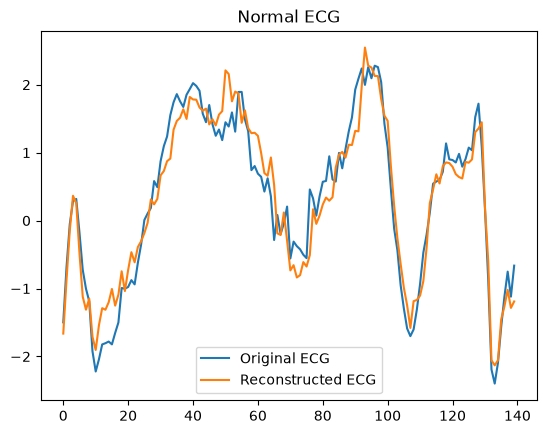

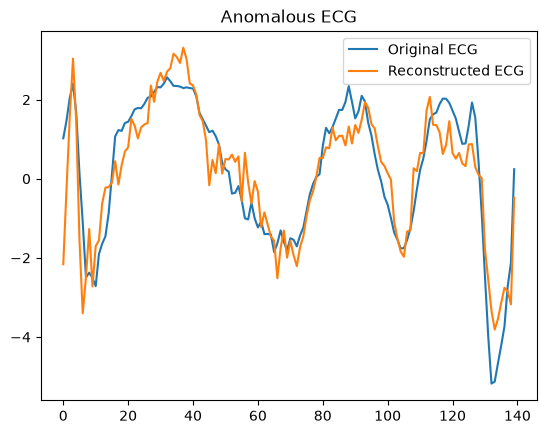

In [6]:

result = model.predict(X_test)


# Normal ECG
plt.plot(X_test[y_test == 1][0], label="Original ECG")
plt.plot(result[y_test == 1][0], label="Reconstructed ECG")
plt.title("Normal ECG")
plt.legend()
plt.show()

# Anomalous ECG
plt.plot(X_test[y_test == 0][0], label="Original ECG")
plt.plot(result[y_test == 0][0], label="Reconstructed ECG")
plt.title("Anomalous ECG")
plt.legend()
plt.show()
